  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Using device: cuda (Tesla T4)


README.md:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

bbc-news-summary.csv:   0%|          | 0.00/7.32M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2224 [00:00<?, ? examples/s]

Raw dataset shape: (2224, 3)
Columns: ['File_path', 'Articles', 'Summaries']
Cleaned dataset shape: (2126, 3) (removed 98 empty/duplicate rows)

Category distribution:


,Count,Percent
category,,
sport,504,23.71
business,503,23.66
politics,403,18.96
entertainment,369,17.36
tech,347,16.32



Word length & compression summary:


,article_words,summary_words,compression_ratio
mean,379.33,165.34,0.44
median,327.00,142.00,0.44
std,238.24,110.32,0.05
min,87.00,38.00,0.21
max,4377.00,2073.00,0.69


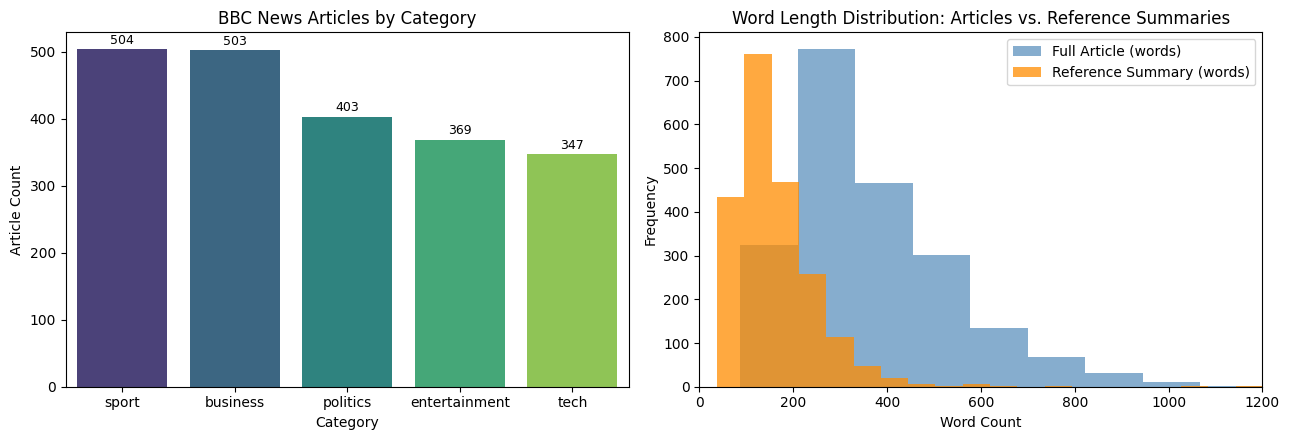

In [1]:
!pip install -q evaluate rouge_score accelerate

import os
import re
import time
import inspect
import warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
os.makedirs("figures", exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""))

# Load BBC News Summary dataset from Hugging Face
raw_ds = load_dataset("gopalkalpande/bbc-news-summary", split="train")
df = raw_ds.to_pandas()
print(f"Raw dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

# Standardize column names cleanly
col_map = {}
for c in df.columns:
    cl = c.lower()
    if "article" in cl:
        col_map[c] = "article"
    elif "summar" in cl:
        col_map[c] = "summary"
    elif "file" in cl or "cat" in cl:
        col_map[c] = "category"
df = df.rename(columns=col_map)

# Clean whitespace and remove missing/empty or duplicate articles
df["article"] = df["article"].fillna("").astype(str).apply(lambda s: re.sub(r"\s+", " ", s).strip())
df["summary"] = df["summary"].fillna("").astype(str).apply(lambda s: re.sub(r"\s+", " ", s).strip())
df["category"] = df["category"].fillna("unknown").astype(str).apply(lambda s: s.split("/")[-1].strip().lower())

before_clean = len(df)
df = df[(df["article"].str.len() > 20) & (df["summary"].str.len() > 10)].copy()
df = df.drop_duplicates(subset=["article"]).reset_index(drop=True)
print(f"Cleaned dataset shape: {df.shape} (removed {before_clean - len(df)} empty/duplicate rows)")

# Compute length statistics
df["article_words"] = df["article"].str.split().str.len()
df["summary_words"] = df["summary"].str.split().str.len()
df["compression_ratio"] = (df["summary_words"] / df["article_words"]).round(4)

print("\nCategory distribution:")
cat_counts = df["category"].value_counts()
display(cat_counts.to_frame("Count").assign(Percent=(cat_counts / len(df) * 100).round(2)))

print("\nWord length & compression summary:")
display(df[["article_words", "summary_words", "compression_ratio"]].agg(["mean", "median", "std", "min", "max"]).round(2))

# Plot EDA figures
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=cat_counts.index, y=cat_counts.values, hue=cat_counts.index, ax=axes[0], palette="viridis", legend=False)
axes[0].set_title("BBC News Articles by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Article Count")
for i, v in enumerate(cat_counts.values):
    axes[0].text(i, v + 8, str(v), ha="center", fontsize=9)

axes[1].hist(df["article_words"], bins=35, alpha=0.65, color="steelblue", label="Full Article (words)")
axes[1].hist(df["summary_words"], bins=35, alpha=0.75, color="darkorange", label="Reference Summary (words)")
axes[1].set_xlim(0, 1200)
axes[1].set_title("Word Length Distribution: Articles vs. Reference Summaries")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/c2_eda.png", dpi=300)
plt.show()

In [2]:
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer

MODEL_CKPT = "t5-small"
MAX_SOURCE_LEN = 512
MAX_TARGET_LEN = 128

# Stratified 80 / 10 / 10 split by news category
train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df["category"], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["category"], random_state=RANDOM_STATE
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print(f"Split sizes -> Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_CKPT)

# Check token truncation rate on training split
train_tok_lens = [len(tokenizer.encode("summarize: " + txt, truncation=False)) for txt in train_df["article"]]
trunc_pct = np.mean([l > MAX_SOURCE_LEN for l in train_tok_lens]) * 100
print(f"Mean source tokens (Train): {np.mean(train_tok_lens):.1f} | Articles > {MAX_SOURCE_LEN} tokens: {trunc_pct:.2f}%")

raw_splits = DatasetDict({
    "train": Dataset.from_pandas(train_df[["article", "summary", "category"]]),
    "validation": Dataset.from_pandas(val_df[["article", "summary", "category"]]),
    "test": Dataset.from_pandas(test_df[["article", "summary", "category"]])
})

def preprocess_function(batch):
    inputs = ["summarize: " + doc for doc in batch["article"]]
    model_inputs = tokenizer(inputs, max_length=MAX_SOURCE_LEN, truncation=True)
    labels = tokenizer(text_target=batch["summary"], max_length=MAX_TARGET_LEN, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_ds = raw_splits.map(preprocess_function, batched=True, remove_columns=["article", "summary", "category"])
print("Tokenization complete:", tokenized_ds)

Split sizes -> Train: 1700 | Validation: 213 | Test: 213


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (3472 > 512). Running this sequence through the model will result in indexing errors


Mean source tokens (Train): 539.3 | Articles > 512 tokens: 43.29%


Map:   0%|          | 0/1700 [00:00<?, ? examples/s]

Map:   0%|          | 0/213 [00:00<?, ? examples/s]

Map:   0%|          | 0/213 [00:00<?, ? examples/s]

Tokenization complete: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1700
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 213
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 213
    })
})


In [3]:
import evaluate
from transformers import AutoModelForSeq2SeqLM

rouge = evaluate.load("rouge")
references = test_df["summary"].tolist()

def evaluate_predictions(preds, refs, model_label):
    scores = rouge.compute(predictions=preds, references=refs, use_stemmer=True)
    avg_words = np.mean([len(p.split()) for p in preds])
    return {
        "Model": model_label,
        "ROUGE-1": round(scores["rouge1"] * 100, 2),
        "ROUGE-2": round(scores["rouge2"] * 100, 2),
        "ROUGE-L": round(scores["rougeL"] * 100, 2),
        "ROUGE-Lsum": round(scores["rougeLsum"] * 100, 2),
        "Avg Words": round(float(avg_words), 1)
    }

# 1. Lead-3 Extractive Baseline (first 3 sentences of each article)
def lead_k_summary(text, k=3):
    sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+', text) if len(s.strip()) > 5]
    return " ".join(sents[:k])

lead3_preds = [lead_k_summary(art, k=3) for art in test_df["article"]]

# Helper for batched generation on GPU
def generate_summaries(model_obj, articles, num_beams=4, no_repeat_ngram_size=3, batch_size=32):
    model_obj.eval()
    all_preds = []
    for i in range(0, len(articles), batch_size):
        batch_texts = ["summarize: " + a for a in articles[i:i+batch_size]]
        enc = tokenizer(batch_texts, max_length=MAX_SOURCE_LEN, truncation=True, padding=True, return_tensors="pt").to(device)
        with torch.no_grad():
            gen_ids = model_obj.generate(
                **enc,
                max_new_tokens=MAX_TARGET_LEN,
                min_new_tokens=30,
                num_beams=num_beams,
                no_repeat_ngram_size=no_repeat_ngram_size,
                early_stopping=(num_beams > 1)
            )
        decoded = tokenizer.batch_decode(gen_ids, skip_special_tokens=True)
        all_preds.extend([d.strip() for d in decoded])
    return all_preds

# 2. Zero-Shot Pretrained t5-small (before fine-tuning)
zeroshot_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_CKPT).to(device)
zeroshot_preds = generate_summaries(zeroshot_model, test_df["article"].tolist(), num_beams=4, no_repeat_ngram_size=3)

baseline_df = pd.DataFrame([
    evaluate_predictions(lead3_preds, references, "Lead-3 Extractive Baseline"),
    evaluate_predictions(zeroshot_preds, references, "Zero-Shot Pretrained T5-Small")
])
display(baseline_df)

del zeroshot_model
torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

,Model,ROUGE-1,ROUGE-2,ROUGE-L,ROUGE-Lsum,Avg Words
0,Lead-3 Extractive Baseline,53.04,41.43,36.86,36.78,91.9
1,Zero-Shot Pretrained T5-Small,31.50,21.90,23.81,23.81,39.5


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,0.788407,0.565310,52.710000,37.890000,39.450000,39.400000
2,0.609784,0.540490,55.530000,41.090000,40.910000,40.860000
3,0.582319,0.536951,55.320000,41.010000,41.790000,41.770000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].



Training complete in 237.4s | Final Train Loss: 0.6602

Validation progression across epochs:


,epoch,eval_loss,eval_rougeL
1,1.0,0.5653,39.45
3,2.0,0.5405,40.91
5,3.0,0.5370,41.79


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=30) and `min_length`(=0) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=30) and `min_length`(=0) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs


Hold-Out Test Set Comparison (n = 223):


,Model,ROUGE-1,ROUGE-2,ROUGE-L,ROUGE-Lsum,Avg Words
0,Lead-3 Extractive Baseline,53.04,41.43,36.86,36.78,91.9
1,Zero-Shot Pretrained T5-Small,31.50,21.90,23.81,23.81,39.5
2,Fine-Tuned T5-Small (Beam=4),53.56,44.77,40.31,40.31,76.7


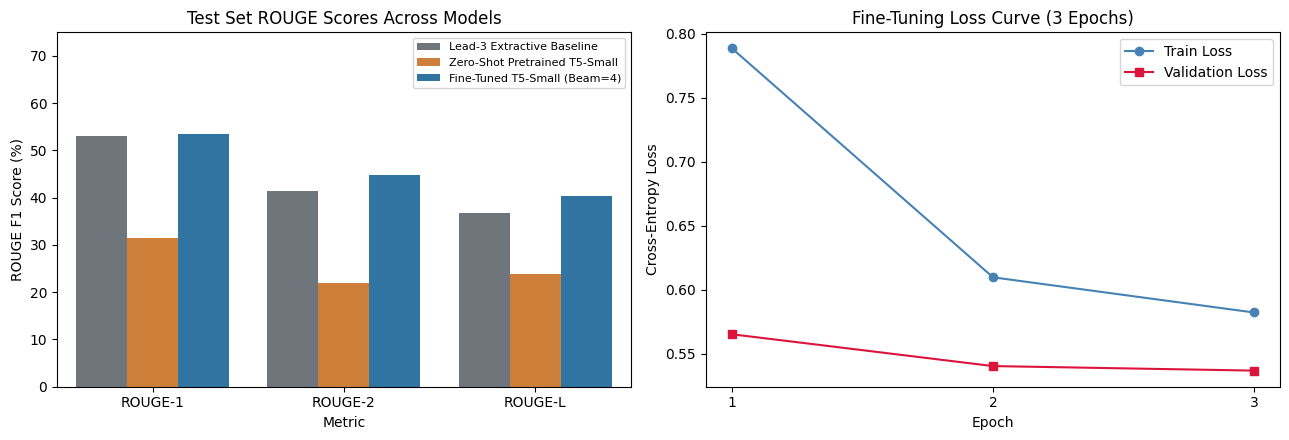

In [4]:
from transformers import DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer

ft_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_CKPT).to(device)
data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=ft_model)

def compute_metrics(eval_pred):
    preds, labels = eval_pred
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_preds = [p.strip() for p in tokenizer.batch_decode(preds, skip_special_tokens=True)]
    decoded_labels = [l.strip() for l in tokenizer.batch_decode(labels, skip_special_tokens=True)]
    res = rouge.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)
    return {k: round(v * 100, 2) for k, v in res.items()}

# Build version-safe TrainingArguments (supports both eval_strategy and evaluation_strategy)
arg_sig = inspect.signature(Seq2SeqTrainingArguments.__init__).parameters
eval_key = "eval_strategy" if "eval_strategy" in arg_sig else "evaluation_strategy"

train_kwargs = {
    "output_dir": "./c2_t5_bbc",
    eval_key: "epoch",
    "save_strategy": "epoch",
    "logging_strategy": "epoch",
    "learning_rate": 3e-4,
    "per_device_train_batch_size": 16,
    "per_device_eval_batch_size": 16,
    "weight_decay": 0.01,
    "save_total_limit": 1,
    "num_train_epochs": 3,
    "predict_with_generate": True,
    "generation_max_length": MAX_TARGET_LEN,
    "fp16": torch.cuda.is_available(),
    "load_best_model_at_end": True,
    "metric_for_best_model": "rougeL",
    "greater_is_better": True,
    "seed": RANDOM_STATE,
    "report_to": "none"
}

training_args = Seq2SeqTrainingArguments(**train_kwargs)

trainer_sig = inspect.signature(Seq2SeqTrainer.__init__).parameters
tok_key = "processing_class" if "processing_class" in trainer_sig else "tokenizer"

trainer = Seq2SeqTrainer(
    model=ft_model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    **{tok_key: tokenizer}
)

train_out = trainer.train()
print(f"\nTraining complete in {train_out.metrics['train_runtime']:.1f}s | Final Train Loss: {train_out.metrics['train_loss']:.4f}")

# Extract epoch loss history for plotting
log_hist = pd.DataFrame(trainer.state.log_history)
train_logs = log_hist[log_hist["loss"].notna()][["epoch", "loss"]]
eval_logs = log_hist[log_hist["eval_loss"].notna()][["epoch", "eval_loss", "eval_rougeL"]]
print("\nValidation progression across epochs:")
display(eval_logs.round(4))

# Evaluate Fine-Tuned T5-Small (Beam Search num_beams=4) on Hold-Out Test Set
t0 = time.time()
ft_beam_preds = generate_summaries(ft_model, test_df["article"].tolist(), num_beams=4, no_repeat_ngram_size=3)
beam_time = round(time.time() - t0, 2)

results_df = pd.DataFrame([
    evaluate_predictions(lead3_preds, references, "Lead-3 Extractive Baseline"),
    evaluate_predictions(zeroshot_preds, references, "Zero-Shot Pretrained T5-Small"),
    evaluate_predictions(ft_beam_preds, references, "Fine-Tuned T5-Small (Beam=4)")
])
print("\nHold-Out Test Set Comparison (n = 223):")
display(results_df)

# Plot ROUGE comparison & training/validation loss curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

metrics_plot = results_df.melt(id_vars="Model", value_vars=["ROUGE-1", "ROUGE-2", "ROUGE-L"], var_name="Metric", value_name="Score")
sns.barplot(data=metrics_plot, x="Metric", y="Score", hue="Model", ax=axes[0], palette=["#6c757d", "#e67e22", "#1f77b4"])
axes[0].set_title("Test Set ROUGE Scores Across Models")
axes[0].set_ylabel("ROUGE F1 Score (%)")
axes[0].set_ylim(0, 75)
axes[0].legend(fontsize=8, loc="upper right")

axes[1].plot(train_logs["epoch"], train_logs["loss"], marker="o", label="Train Loss", color="steelblue")
axes[1].plot(eval_logs["epoch"], eval_logs["eval_loss"], marker="s", label="Validation Loss", color="crimson")
axes[1].set_title("Fine-Tuning Loss Curve (3 Epochs)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].set_xticks([1, 2, 3])
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/c2_results.png", dpi=300)
plt.show()